# 05b — Tuning: every option tried, and why the settings of notebook 05 were chosen

Notebook 05 reports the main machine-learning results with small tuning grids. This notebook documents the choice: how many trees a forest needs, how every combination of settings performs, whether a wider search helps, and whether tuning with canton folds (the way the models are tested) changes the conclusion.

Every score is out of sample: each commune is predicted by a model trained without it, with random folds or with folds that hold out whole cantons (the same folds as notebook 05).

Input: `data/processed/communes_2022.csv`, `Results/ml/table_tuning_forest_boosting.csv` (settings chosen in notebook 05). Output: `Results/tuning/`. Running time: about 35 minutes.

## 1. Setup: the same data, features and folds as notebook 05

In [1]:
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import r2_score
from sklearn.model_selection import (GridSearchCV, GroupKFold, KFold, RandomizedSearchCV,
                                     cross_val_predict)
sys.path.append("../code")
import helpers

df, tax_sample, sa_sample = helpers.load_model_samples()
OUT = helpers.results_dir("tuning")

# Same features, outcomes and folds as notebook 05
outcomes = {
    "Tax (log)":    (helpers.ml_features(tax_sample), tax_sample["log_tax"], tax_sample["canton"]),
    "SA rate (pp)": (helpers.ml_features(sa_sample), sa_sample["sa_rate"], sa_sample["canton"]),
}
random_cv = KFold(n_splits=5, shuffle=True, random_state=helpers.SEED)
canton_cv = GroupKFold(n_splits=5, shuffle=True, random_state=helpers.SEED)
schemes = {"random folds": random_cv, "canton folds": canton_cv}


def oof_r2(model, X, y, cantons, scheme):
    """Out-of-sample R²: every commune is predicted by a model trained on the other folds."""
    groups = cantons if scheme == "canton folds" else None
    pred = cross_val_predict(model, X, y, cv=schemes[scheme], groups=groups, n_jobs=-1)
    return r2_score(y, pred)


# Settings chosen in notebook 05 (section 4), to mark them in the figures below
tuned_05 = pd.read_csv(helpers.ROOT / "Results" / "ml" / "table_tuning_forest_boosting.csv", index_col=[0, 1])
leaf_05 = {label: int(tuned_05.loc[("Random forest", label), "min_samples_leaf"]) for label in outcomes}
print("Leaf size chosen in notebook 05:", leaf_05)

Leaf size chosen in notebook 05: {'Tax (log)': 1, 'SA rate (pp)': 5}


## 2. How many trees does a forest need?

A random forest averages many trees; more trees make the average more stable but do not change the model. Here the forest of notebook 05 (a third of the features at each question, the leaf size chosen in notebook 05) is grown with 25 to 500 trees.

outcome    Tax (log)              SA rate (pp)             
scheme  random folds canton folds random folds canton folds
trees                                                      
25             0.313        0.185        0.271        0.122
50             0.332        0.195        0.276        0.136
100            0.337        0.201        0.282        0.142
200            0.345        0.206        0.284        0.146
300            0.346        0.208        0.283        0.146
500            0.347        0.209        0.285        0.144

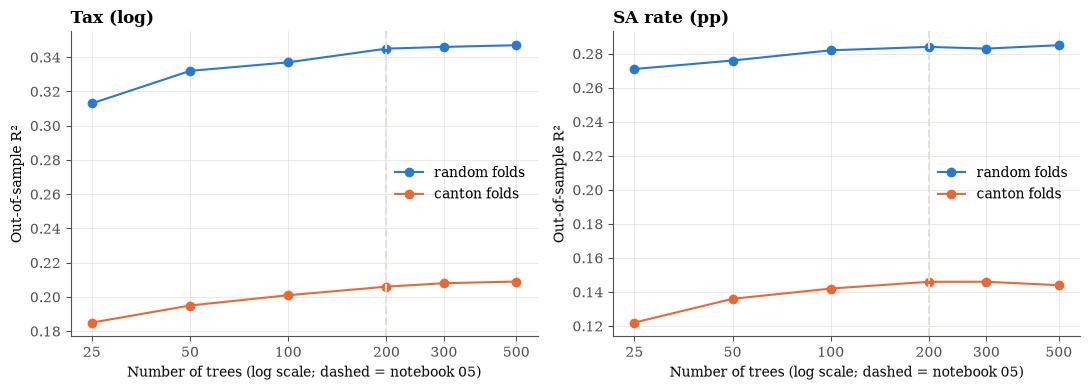

In [2]:
tree_counts = [25, 50, 100, 200, 300, 500]
rows = []
for label, (X, y, cantons) in outcomes.items():
    for scheme in schemes:
        for n in tree_counts:
            model = RandomForestRegressor(n_estimators=n, max_features=0.33,
                                          min_samples_leaf=leaf_05[label], random_state=helpers.SEED)
            rows.append({"outcome": label, "scheme": scheme, "trees": n,
                         "R²": oof_r2(model, X, y, cantons, scheme)})
table_trees = pd.DataFrame(rows).pivot_table(index="trees", columns=["outcome", "scheme"],
                                             values="R²", sort=False).round(3)
table_trees.to_csv(OUT / "table_number_of_trees.csv")
display(table_trees)

scheme_colors = {"random folds": helpers.COLORS["urban_rural"]["urban"],
                 "canton folds": helpers.COLORS["urban_rural"]["intermediate"]}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, label in zip(axes, outcomes):
    for scheme, color in scheme_colors.items():
        ax.plot(tree_counts, table_trees[(label, scheme)], marker="o", color=color, label=scheme)
    ax.axvline(200, color=helpers.INK["grid"], linestyle="--")
    ax.set_xscale("log")
    ax.minorticks_off()
    ax.set_xticks(tree_counts, tree_counts)
    ax.set_xlabel("Number of trees (log scale; dashed = notebook 05)")
    ax.set_ylabel("Out-of-sample R²")
    ax.set_title(label)
    ax.legend()
    ax.grid(color=helpers.INK["grid"], linewidth=0.5)
fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_number_of_trees.png")
plt.show()

**Interpretation.** R² rises quickly up to about 100 trees and is flat from 200 trees on (300 and 500 trees add at most 0.003). The 200 trees of notebook 05 are therefore enough: more trees make the average marginally more stable but do not change the model. Fewer trees (25–50) clearly lose accuracy, especially across cantons.

## 3. Random forest: every combination of settings

Two settings matter most: the share of the features a tree may choose from at each question (`max_features`; small = more different trees) and the minimum number of communes in a leaf (`min_samples_leaf`; large = smoother trees). All 15 combinations are scored with both kinds of folds (200 trees, as in notebook 05). The box marks the setting used in notebook 05.

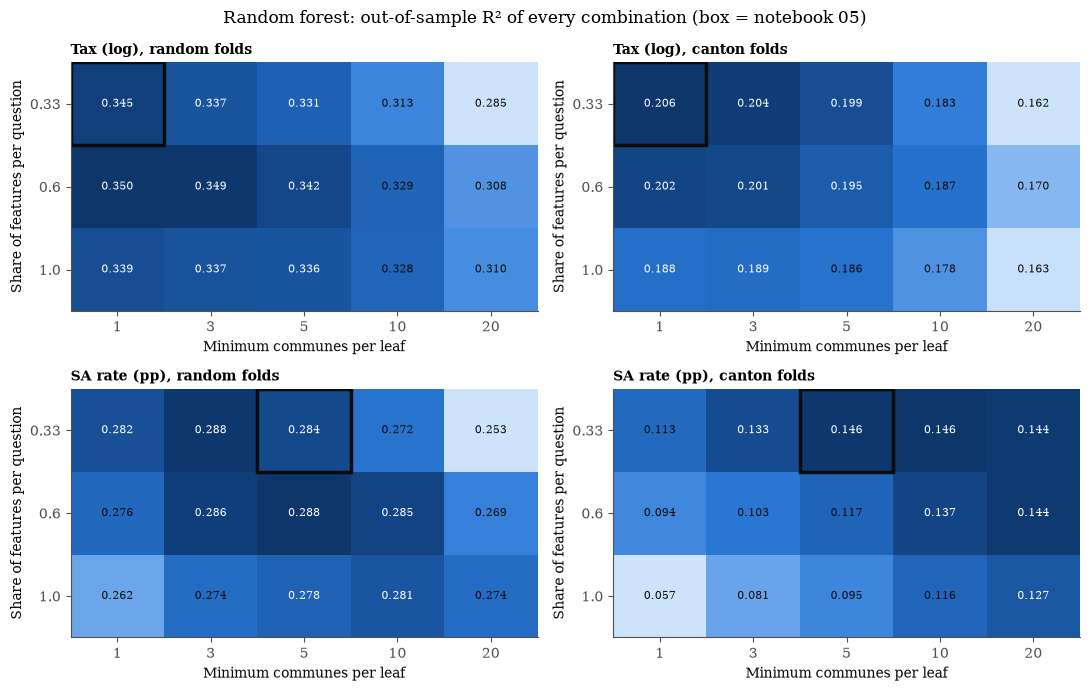

max_features  min_samples_leaf     R²
outcome      scheme                                             
SA rate (pp) canton folds          0.33                10  0.146
             random folds          0.60                 5  0.288
Tax (log)    canton folds          0.33                 1  0.206
             random folds          0.60                 1  0.350

In [3]:
feature_shares = [0.33, 0.6, 1.0]
leaf_sizes = [1, 3, 5, 10, 20]

rows = []
for label, (X, y, cantons) in outcomes.items():
    for scheme in schemes:
        for share in feature_shares:
            for leaf in leaf_sizes:
                model = RandomForestRegressor(n_estimators=200, max_features=share,
                                              min_samples_leaf=leaf, random_state=helpers.SEED)
                rows.append({"outcome": label, "scheme": scheme, "max_features": share,
                             "min_samples_leaf": leaf, "R²": oof_r2(model, X, y, cantons, scheme)})
forest_grid = pd.DataFrame(rows)
forest_grid.round(4).to_csv(OUT / "table_forest_grid.csv", index=False)


def heatmap(ax, table, title, mark=None):
    """R² of every combination as coloured cells with the value written in each cell;
    `mark` = (row label, column label) of the setting to outline."""
    values = table.to_numpy()
    image = ax.imshow(values, cmap=helpers.SEQUENTIAL, aspect="auto")
    ax.set_xticks(range(values.shape[1]), table.columns)
    ax.set_yticks(range(values.shape[0]), table.index)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            dark = values[i, j] > np.nanmean(values)
            ax.text(j, i, f"{values[i, j]:.3f}", ha="center", va="center", fontsize=8,
                    color="white" if dark else helpers.INK["primary"])
    if mark is not None:
        i, j = list(table.index).index(mark[0]), list(table.columns).index(mark[1])
        ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, linewidth=2.5,
                               edgecolor=helpers.INK["primary"]))
    ax.set_title(title, fontsize=10)
    return image


fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for row, label in enumerate(outcomes):
    for col, scheme in enumerate(schemes):
        part = forest_grid[(forest_grid["outcome"] == label) & (forest_grid["scheme"] == scheme)]
        table = part.pivot(index="max_features", columns="min_samples_leaf", values="R²")
        heatmap(axes[row, col], table, f"{label}, {scheme}", mark=(0.33, leaf_05[label]))
        axes[row, col].set_xlabel("Minimum communes per leaf")
        axes[row, col].set_ylabel("Share of features per question")
fig.suptitle("Random forest: out-of-sample R² of every combination (box = notebook 05)")
fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_forest_grid.png")
plt.show()

best_forest = (forest_grid.loc[forest_grid.groupby(["outcome", "scheme"])["R²"].idxmax()]
               .set_index(["outcome", "scheme"]).round(3))
display(best_forest)

**Interpretation.** The two kinds of folds prefer different settings. With random folds the best forests use 60% of the features at each question (R² 0.350 for tax, 0.288 for SA). Across cantons, a third of the features is best for tax (0.206, exactly the setting of notebook 05) and, for SA, a third of the features with larger leaves (5–10 communes; 0.146, the setting of notebook 05 ties with the best). Using all features at each question is clearly worse across cantons for SA (down to 0.057): when every tree can use every feature, the trees are all alike and learn the same canton-specific patterns. The settings of notebook 05 are the best or tied with the best on the honest test.

## 4. Gradient boosting: every combination, with early stopping

Boosting adds small trees one after the other. Here it may run up to 1,000 rounds but stops when 10% of the training communes, kept aside, stop improving for 20 rounds (early stopping), so the number of rounds is chosen automatically. Tried: learning rate (0.01, 0.03, 0.1) × tree depth (2, 3, 5, 8) × L2 penalty on the leaf values (0, 1) = 24 combinations, with both kinds of folds.

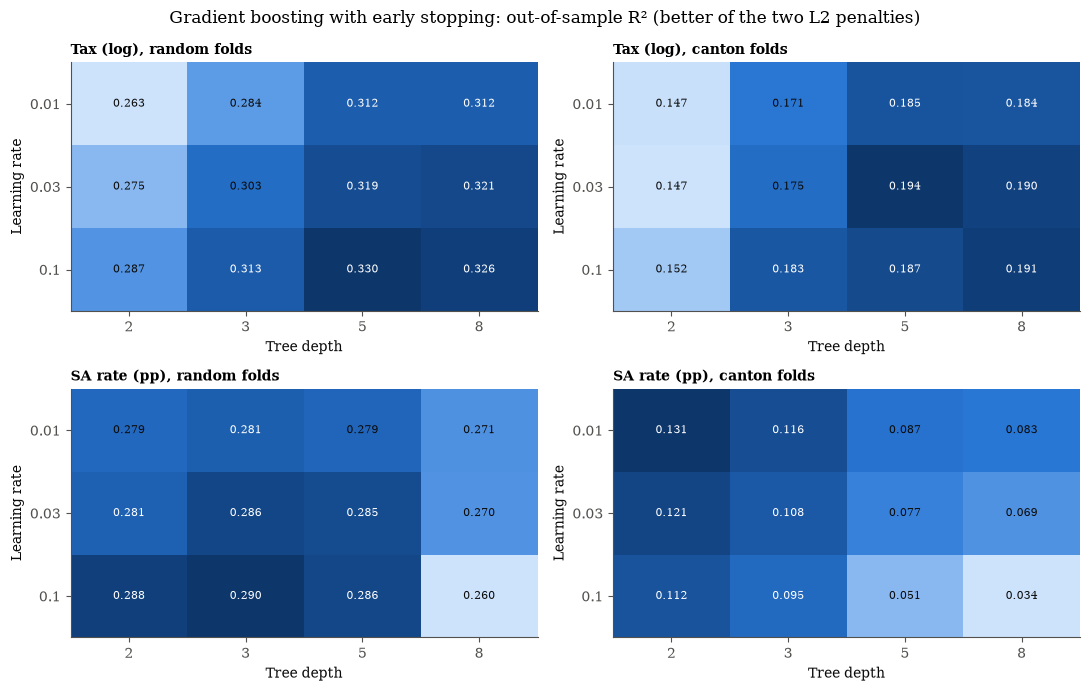

learning_rate  max_depth  l2_regularization     R²
outcome      scheme                                                          
SA rate (pp) canton folds           0.01          2                  1  0.131
             random folds           0.10          3                  0  0.290
Tax (log)    canton folds           0.03          5                  1  0.194
             random folds           0.10          5                  0  0.330

learning rate,0.01,0.03,0.10
outcome,,,
SA rate (pp),528,205,74
Tax (log),735,291,336


In [4]:
learning_rates = [0.01, 0.03, 0.1]
depths = [2, 3, 5, 8]
penalties = [0, 1]

rows = []
for label, (X, y, cantons) in outcomes.items():
    for scheme in schemes:
        for rate in learning_rates:
            for depth in depths:
                for penalty in penalties:
                    model = HistGradientBoostingRegressor(
                        max_iter=1000, early_stopping=True, validation_fraction=0.1,
                        n_iter_no_change=20, learning_rate=rate, max_depth=depth,
                        l2_regularization=penalty, random_state=helpers.SEED)
                    rows.append({"outcome": label, "scheme": scheme, "learning_rate": rate,
                                 "max_depth": depth, "l2_regularization": penalty,
                                 "R²": oof_r2(model, X, y, cantons, scheme)})
boosting_grid = pd.DataFrame(rows)
boosting_grid.round(4).to_csv(OUT / "table_boosting_grid.csv", index=False)

# Heatmaps: learning rate x depth, keeping the better of the two penalties in each cell
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for row, label in enumerate(outcomes):
    for col, scheme in enumerate(schemes):
        part = boosting_grid[(boosting_grid["outcome"] == label) & (boosting_grid["scheme"] == scheme)]
        table = part.groupby(["learning_rate", "max_depth"])["R²"].max().unstack()
        heatmap(axes[row, col], table, f"{label}, {scheme}")
        axes[row, col].set_xlabel("Tree depth")
        axes[row, col].set_ylabel("Learning rate")
fig.suptitle("Gradient boosting with early stopping: out-of-sample R² (better of the two L2 penalties)")
fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_boosting_grid.png")
plt.show()

best_boosting = (boosting_grid.loc[boosting_grid.groupby(["outcome", "scheme"])["R²"].idxmax()]
                 .set_index(["outcome", "scheme"]).round(3))
display(best_boosting)

# How many rounds does early stopping keep? (all communes, depth 3, no penalty)
rounds = {}
for label, (X, y, cantons) in outcomes.items():
    for rate in learning_rates:
        fitted = HistGradientBoostingRegressor(max_iter=1000, early_stopping=True, validation_fraction=0.1,
                                               n_iter_no_change=20, learning_rate=rate, max_depth=3,
                                               random_state=helpers.SEED).fit(X, y)
        rounds[(label, rate)] = fitted.n_iter_
table_rounds = pd.Series(rounds).unstack().rename_axis(index="outcome", columns="learning rate")
table_rounds.to_csv(OUT / "table_boosting_rounds.csv")
display(table_rounds)

**Interpretation.** With early stopping, the best boosting models reach R² 0.330 (tax) and 0.290 (SA) with random folds, but only 0.194 and 0.131 across cantons, below the random forest in both cases. Again the two tests disagree: random folds prefer a fast learning rate (0.1), canton folds a slow one (0.01–0.03) and, for SA, shallow trees (depth 2); deep trees with a fast learning rate collapse across cantons (SA: 0.034). Early stopping keeps 74 to 735 rounds depending on the learning rate: a slower learning rate needs more, smaller corrections.

## 5. Does a wider search help? The search of notebook 05 against a wider randomized search

Both are nested: the settings are chosen inside each training fold with 5 inner **random** folds, then the model predicts the held-out fold.

- **Narrow** (notebook 05): forest leaf size {1, 5, 20} with a third of the features and 200 trees; boosting depth {2, 3, 5} × learning rate {0.03, 0.1}, 300 rounds.
- **Wide**: 12 random combinations out of the 15 forest combinations of section 3 (300 trees) and out of 18 boosting combinations of section 4 (with early stopping).

In [5]:
def forest_search(kind, inner_cv):
    """Random-forest tuning: 'narrow' = notebook 05, 'wide' = randomized search on the full grid."""
    if kind == "narrow":
        return GridSearchCV(RandomForestRegressor(n_estimators=200, max_features=0.33, random_state=helpers.SEED),
                            {"min_samples_leaf": [1, 5, 20]}, cv=inner_cv, scoring="r2")
    return RandomizedSearchCV(RandomForestRegressor(n_estimators=300, random_state=helpers.SEED),
                              {"max_features": feature_shares, "min_samples_leaf": leaf_sizes},
                              n_iter=12, cv=inner_cv, scoring="r2", random_state=helpers.SEED)


def boosting_search(kind, inner_cv):
    """Boosting tuning: 'narrow' = notebook 05, 'wide' = randomized search with early stopping."""
    if kind == "narrow":
        return GridSearchCV(HistGradientBoostingRegressor(max_iter=300, random_state=helpers.SEED),
                            {"max_depth": [2, 3, 5], "learning_rate": [0.03, 0.1]}, cv=inner_cv, scoring="r2")
    return RandomizedSearchCV(
        HistGradientBoostingRegressor(max_iter=1000, early_stopping=True, validation_fraction=0.1,
                                      n_iter_no_change=20, random_state=helpers.SEED),
        {"learning_rate": learning_rates, "max_depth": [3, 5, 8], "l2_regularization": penalties},
        n_iter=12, cv=inner_cv, scoring="r2", random_state=helpers.SEED)


searches = {"Random forest": forest_search, "Gradient boosting": boosting_search}
inner_random = KFold(n_splits=5, shuffle=True, random_state=helpers.SEED)

rows = []
for name, make_search in searches.items():
    for kind in ["narrow", "wide"]:
        for label, (X, y, cantons) in outcomes.items():
            for scheme in schemes:
                start = time.perf_counter()
                r2 = oof_r2(make_search(kind, inner_random), X, y, cantons, scheme)
                rows.append({"model": name, "search": kind, "inner folds": "random",
                             "outcome": label, "scheme": scheme, "R²": r2,
                             "minutes": (time.perf_counter() - start) / 60})
nested = pd.DataFrame(rows)
table_nested = nested.pivot_table(index=["model", "search"], columns=["outcome", "scheme"],
                                  values="R²", sort=False).round(3)
table_nested.to_csv(OUT / "table_narrow_vs_wide.csv")
display(table_nested)
print("Minutes per model and search (4 runs each):")
display(nested.groupby(["model", "search"], sort=False)["minutes"].sum().round(1))

outcome                     Tax (log)              SA rate (pp)             
scheme                   random folds canton folds random folds canton folds
model             search                                                    
Random forest     narrow        0.345        0.204        0.284        0.136
                  wide          0.344        0.199        0.284        0.091
Gradient boosting narrow        0.327        0.195        0.279        0.119
                  wide          0.309        0.183        0.287        0.066

Minutes per model and search (4 runs each):


model              search
Random forest      narrow    0.9
                   wide      7.8
Gradient boosting  narrow    0.8
                   wide      2.1
Name: minutes, dtype: float64

**Interpretation.** A wider randomized search does not help. With random folds it changes R² by at most ±0.02; across cantons it is worse, clearly so for SA (forest 0.136 → 0.091, boosting 0.119 → 0.066), and it takes several times longer (forest: 8.1 against 1.1 minutes). The wider search picks the flexible settings that win on the random inner folds (sections 3 and 4), and these settings do not carry over to cantons the model has never seen. More combinations are only better if they are judged the way the model will be used.

## 6. Tuning the way we test: canton folds inside the training data

In section 5, the settings are chosen with inner **random** folds even when the model is then tested on **unseen cantons**. A search can then favour flexible settings that exploit patterns specific to known cantons. Here, for the canton-fold test only, the inner folds also hold out whole cantons, so the settings are chosen for the same task they are tested on.

In [6]:
def nested_canton(make_search, kind, X, y, cantons):
    """Canton folds outside AND inside: each held-out group of cantons is predicted by a model
    whose settings were chosen with folds that also hold out whole cantons."""
    pred = np.empty(len(y))
    for train, test in canton_cv.split(X, y, groups=cantons):
        inner_canton = GroupKFold(n_splits=5, shuffle=True, random_state=helpers.SEED)
        search = make_search(kind, inner_canton)
        search.set_params(n_jobs=-1)
        search.fit(X.iloc[train], y.iloc[train], groups=cantons.iloc[train])
        pred[test] = search.predict(X.iloc[test])
    return r2_score(y, pred)


rows = []
for name, make_search in searches.items():
    for kind in ["narrow", "wide"]:
        for label, (X, y, cantons) in outcomes.items():
            start = time.perf_counter()
            r2 = nested_canton(make_search, kind, X, y, cantons)
            rows.append({"model": name, "search": kind, "inner folds": "canton",
                         "outcome": label, "scheme": "canton folds", "R²": r2,
                         "minutes": (time.perf_counter() - start) / 60})
nested_canton_table = pd.DataFrame(rows)

comparison = (pd.concat([nested[nested["scheme"] == "canton folds"], nested_canton_table])
              .pivot_table(index=["model", "search"], columns=["outcome", "inner folds"],
                           values="R²", sort=False).round(3))
comparison.to_csv(OUT / "table_inner_folds.csv")
display(comparison)

outcome                  Tax (log) SA rate (pp) Tax (log) SA rate (pp)
inner folds                 random       random    canton       canton
model             search                                              
Random forest     narrow     0.204        0.136     0.173        0.145
                  wide       0.199        0.091     0.181        0.140
Gradient boosting narrow     0.195        0.119     0.166        0.135
                  wide       0.183        0.066     0.163        0.093

**Interpretation.** Choosing the settings with canton folds inside the training data helps for social assistance: every variant improves across cantons (forest 0.136 → 0.145, wide boosting 0.066 → 0.093), and the wide search no longer breaks down. For tax it costs accuracy (forest 0.204 → 0.173): with only about 20 cantons in each training set, the inner canton folds are few and very different from each other, so the choice of settings is noisier and tends towards smoother models that underfit tax. No tuning scheme is best for both outcomes; the narrow search of notebook 05 is the best for tax and within 0.01 of the best for SA.

## 7. All options side by side

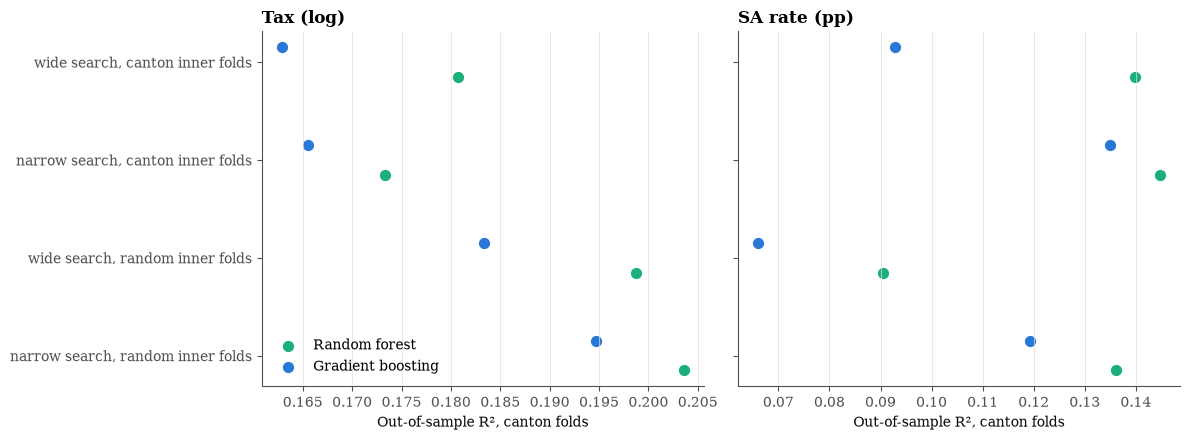

In [7]:
everything = pd.concat([nested, nested_canton_table], ignore_index=True)
everything["variant"] = everything["search"] + " search, " + everything["inner folds"] + " inner folds"
everything.round(4).to_csv(OUT / "table_all_tuning_variants.csv", index=False)

# Figure: canton-fold R² (the honest test) of every variant, with the random-fold R² for reference
variant_order = ["narrow search, random inner folds", "wide search, random inner folds",
                 "narrow search, canton inner folds", "wide search, canton inner folds"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, label in zip(axes, outcomes):
    for offset, (name, color) in zip([-0.15, 0.15], [("Random forest", helpers.COLORS["urban_rural"]["rural"]),
                                                     ("Gradient boosting", helpers.COLORS["urban_rural"]["urban"])]):
        part = everything[(everything["outcome"] == label) & (everything["model"] == name)
                          & (everything["scheme"] == "canton folds")].set_index("variant").reindex(variant_order)
        ax.scatter(part["R²"], np.arange(len(variant_order)) + offset, color=color, s=50, label=name)
    ax.set_yticks(range(len(variant_order)), variant_order)
    ax.invert_yaxis()
    ax.set_xlabel("Out-of-sample R², canton folds")
    ax.set_title(label)
    ax.grid(axis="x", color=helpers.INK["grid"], linewidth=0.5)
axes[0].legend(loc="lower left")
fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_tuning_variants.png")
plt.show()

paper_tables = {"table_number_of_trees": table_trees, "table_narrow_vs_wide": table_nested,
                "table_inner_folds": comparison}
for name, table in paper_tables.items():
    _ = (OUT / f"{name}.tex").write_text(table.to_latex(escape=True, na_rep="", float_format="%.3f"),
                                         encoding="utf-8")

## 8. Summary

| Question | Answer |
|---|---|
| How many trees? | 200 are enough: R² is flat from 200 to 500 trees |
| Best random-forest settings? | random folds prefer more features per question (60%); across cantons, a third of the features is best, which is the setting of notebook 05 |
| Best boosting settings? | random folds prefer a fast learning rate; across cantons a slow one and shallow trees; boosting stays below the forest in every case |
| Does a wider search help? | no: similar with random folds, worse across cantons (SA forest 0.136 → 0.091), and several times slower |
| Does tuning with canton folds help? | for SA yes (0.136 → 0.145), for tax no (0.204 → 0.173); no scheme is best for both |

The settings of notebook 05 are the best or nearly the best on the honest test (unseen cantons), so its results do not depend on a narrow search. The main conclusions are unchanged by any tuning choice: flexible models predict tax clearly better than OLS across cantons (best forest 0.206 against 0.101), and social assistance only slightly better (best 0.146 against 0.103). The general lesson is that tuning optimises for the validation scheme it uses: when the goal is to predict new regions, settings tuned on random folds favour flexibility that learns region-specific patterns.